# ARTI 502 | Deep Learning 2st Assignmet
## Training-Testing CNN with CIFAR Dataset using Pytorc

In [1]:
# Task 1
import torchvision
import torchvision.transforms as transforms

In [2]:
# Define an empty directory path
DATA_PATH = './cifar_data'

# Download the CIFAR dataset using the helper function
trainset = torchvision.datasets.CIFAR10(root=DATA_PATH, train=True, download=True, transform=transforms.ToTensor())

print("CIFAR Dataset loaded successfully!")

100%|██████████| 170M/170M [05:23<00:00, 527kB/s]


CIFAR Dataset loaded successfully!


In [3]:
# Task 2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torch.utils.data as DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        # 1st convolutional layer
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=1)

        # Max pooling layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # 2nd convolutional layer
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1)

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        # 1st convolution block
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)

        # 2nd convolution block
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        # Flatten feature maps
        x = torch.flatten(x, start_dim=1)

        # Fully connected layers
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

model = CNN().to(device)

print(model)

CNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [5]:
def train(model, loader, criterion, optimizer, epochs=10):

    train_losses = []
    train_accuracies = []

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

        epoch_loss = running_loss / total
        epoch_accuracy = 100 * correct / total

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_accuracy)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {epoch_loss:.4f} | "
            f"Train Acc: {epoch_accuracy:.2f}%"
        )

    return train_losses, train_accuracies

In [6]:
def test(model, loader, criterion):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predicted = outputs.argmax(1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    print(
        f"Test Loss: {test_loss:.4f} | "
        f"Test Accuracy: {test_accuracy:.2f}%"
    )

    return test_loss, test_accuracy

In [7]:
# Task 3
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

BATCH_SIZE = 32

train_loader = DataLoader(
    trainset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [8]:
images, labels = next(iter(train_loader))

In [9]:
print("Images Tensor Size:", images.size())
print("Labels Tensor Size:", labels.size())

Images Tensor Size: torch.Size([32, 3, 32, 32])
Labels Tensor Size: torch.Size([32])


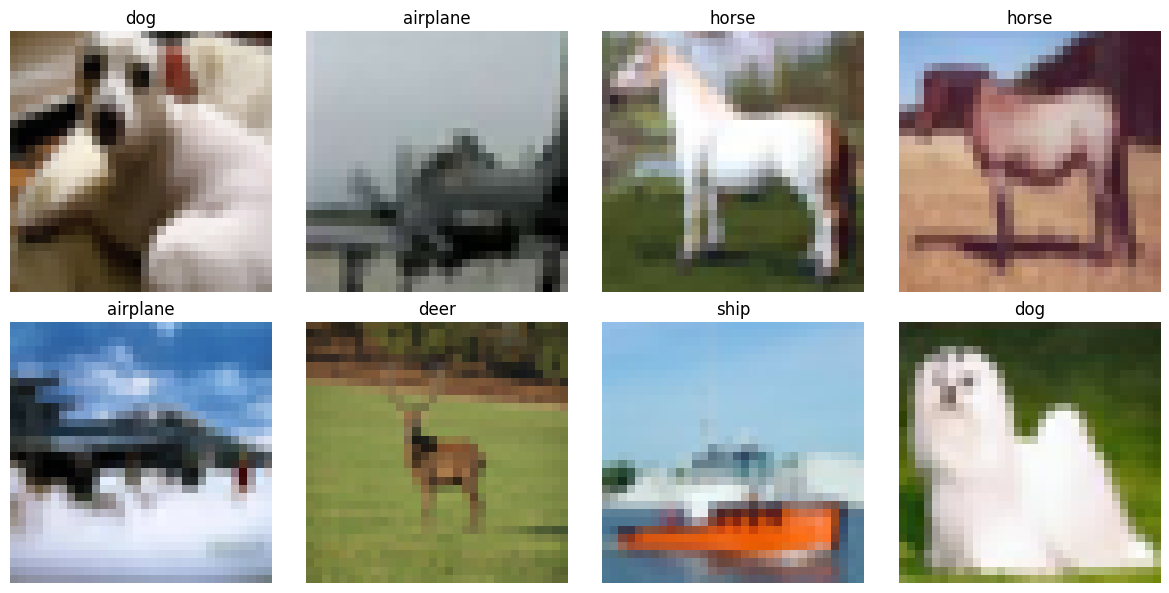

In [10]:
import matplotlib.pyplot as plt

classes = trainset.classes

plt.figure(figsize=(12, 6))

for i in range(8):
    image = images[i].permute(1, 2, 0)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(classes[labels[i].item()])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [11]:
# Task 4

import torchvision.transforms as transforms
import torchvision.datasets as datasets

# CIFAR-10 normalization values
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

# Training transformations
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Testing transformations (No random augmentation)
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Training dataset with augmentation
trainset = datasets.CIFAR10(
    root=DATA_PATH,
    train=True,
    download=True,
    transform=train_transform
)

# Testing dataset without augmentation
testset = datasets.CIFAR10(
    root=DATA_PATH,
    train=False,
    download=True,
    transform=test_transform
)

print("Training and Testing transformations applied successfully!")
print("Training dataset size:", len(trainset))
print("Testing dataset size:", len(testset))

Training and Testing transformations applied successfully!
Training dataset size: 50000
Testing dataset size: 10000


In [12]:
# Create DataLoaders

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    trainset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_loader = DataLoader(
    testset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Test batches:", len(test_loader))

Train batches: 1563
Test batches: 313


Images shape: torch.Size([32, 3, 32, 32])
Labels shape: torch.Size([32])


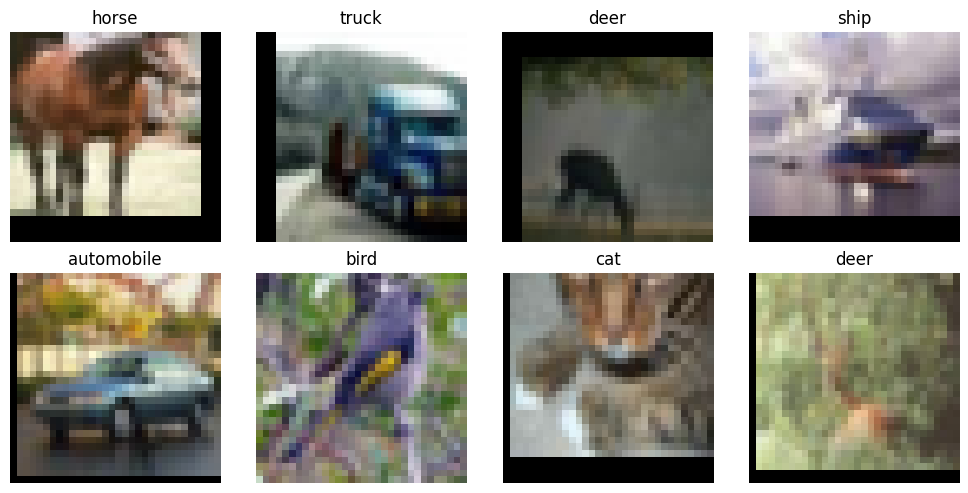

In [13]:
# Check augmented images

images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for i in range(8):
    img = images[i].permute(1, 2, 0)

    # Reverse normalization for visualization
    img = img * torch.tensor(std) + torch.tensor(mean)
    img = img.clamp(0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(trainset.classes[labels[i].item()])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [14]:
# Task 5: Training, Hyperparameter Tuning & Results
#Tuning uses a **validation split** carved from the training set (the test set is only used once, at the end).
import os, json, time, itertools
import numpy as np
import pandas as pd
from torch.utils.data import Subset, DataLoader

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
os.makedirs("results", exist_ok=True)

# 45k train / 5k validation split
full_train_aug   = datasets.CIFAR10(DATA_PATH, train=True, download=True, transform=train_transform)
full_train_clean = datasets.CIFAR10(DATA_PATH, train=True, download=True, transform=test_transform)
perm = np.random.permutation(len(full_train_aug))
train_idx, val_idx = perm[:45000], perm[45000:]

train_ds = Subset(full_train_aug, train_idx)     # augmented
val_ds   = Subset(full_train_clean, val_idx)     # no augmentation
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=2)
print(len(train_ds), len(val_ds), len(testset))

45000 5000 10000


In [15]:
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss_sum += criterion(out, y).item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)
    return loss_sum / total, 100 * correct / total


def make_optimizer(model, cfg):
    if cfg["optimizer"] == "SGD":
        return optim.SGD(model.parameters(), lr=cfg["lr"], momentum=0.9, weight_decay=cfg["wd"])
    return optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])


def fit(cfg, epochs, train_loader, val_loader, verbose=False):
    model = CNN().to(device)
    criterion = nn.CrossEntropyLoss()
    opt = make_optimizer(model, cfg)
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for ep in range(epochs):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            opt.step()
            loss_sum += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

        v_loss, v_acc = evaluate(model, val_loader, criterion)
        hist["train_loss"].append(loss_sum / total)
        hist["train_acc"].append(100 * correct / total)
        hist["val_loss"].append(v_loss)
        hist["val_acc"].append(v_acc)
        if verbose:
            print(f"Epoch {ep+1}/{epochs} | Train Loss {hist['train_loss'][-1]:.4f} "
                  f"Acc {hist['train_acc'][-1]:.2f}% | Val Loss {v_loss:.4f} Acc {v_acc:.2f}%")
    return model, hist

In [16]:
## Hyperparameter search (5 epochs per config)
grid = {
    "lr":        [0.01, 0.001],
    "optimizer": ["SGD", "Adam"],
    "batch_size":[64, 128],
    "wd":        [0.0, 5e-4],
}
TUNE_EPOCHS = 5

results = []
keys = list(grid.keys())
for values in itertools.product(*grid.values()):
    cfg = dict(zip(keys, values))
    torch.manual_seed(SEED)
    tl = DataLoader(train_ds, batch_size=cfg["batch_size"], shuffle=True, num_workers=2)
    t0 = time.time()
    _, h = fit(cfg, TUNE_EPOCHS, tl, val_loader)
    row = {**cfg,
           "final_train_loss": h["train_loss"][-1], "final_train_acc": h["train_acc"][-1],
           "final_val_loss":   h["val_loss"][-1],   "final_val_acc":   h["val_acc"][-1],
           "best_val_acc": max(h["val_acc"]), "time_s": round(time.time() - t0, 1)}
    results.append(row)
    print(cfg, f"-> val acc {row['final_val_acc']:.2f}%  val loss {row['final_val_loss']:.4f}")

tune_df = pd.DataFrame(results).sort_values("final_val_acc", ascending=False).reset_index(drop=True)
tune_df.to_csv("results/tuning_results.csv", index=False)
tune_df.round(4)

{'lr': 0.01, 'optimizer': 'SGD', 'batch_size': 64, 'wd': 0.0} -> val acc 67.64%  val loss 0.9186
{'lr': 0.01, 'optimizer': 'SGD', 'batch_size': 64, 'wd': 0.0005} -> val acc 68.32%  val loss 0.8959
{'lr': 0.01, 'optimizer': 'SGD', 'batch_size': 128, 'wd': 0.0} -> val acc 66.78%  val loss 0.9576
{'lr': 0.01, 'optimizer': 'SGD', 'batch_size': 128, 'wd': 0.0005} -> val acc 66.74%  val loss 0.9664
{'lr': 0.01, 'optimizer': 'Adam', 'batch_size': 64, 'wd': 0.0} -> val acc 10.48%  val loss 2.3032
{'lr': 0.01, 'optimizer': 'Adam', 'batch_size': 64, 'wd': 0.0005} -> val acc 37.92%  val loss 1.6566
{'lr': 0.01, 'optimizer': 'Adam', 'batch_size': 128, 'wd': 0.0} -> val acc 10.48%  val loss 2.3028
{'lr': 0.01, 'optimizer': 'Adam', 'batch_size': 128, 'wd': 0.0005} -> val acc 38.08%  val loss 1.6466
{'lr': 0.001, 'optimizer': 'SGD', 'batch_size': 64, 'wd': 0.0} -> val acc 54.76%  val loss 1.2786
{'lr': 0.001, 'optimizer': 'SGD', 'batch_size': 64, 'wd': 0.0005} -> val acc 54.58%  val loss 1.2830
{'lr'

,lr,optimizer,batch_size,wd,final_train_loss,final_train_acc,final_val_loss,final_val_acc,best_val_acc,time_s
0,0.001,Adam,128,0.0000,0.9769,65.4578,0.8804,69.86,69.86,82.2
1,0.001,Adam,64,0.0000,0.9465,66.4667,0.8745,69.38,69.38,88.3
2,0.001,Adam,128,0.0005,0.9985,64.7400,0.9089,68.88,68.88,84.7
3,0.001,Adam,64,0.0005,0.9697,65.6689,0.8885,68.34,68.34,87.0
4,0.010,SGD,64,0.0005,0.9349,66.9689,0.8959,68.32,68.32,80.7
5,0.010,SGD,64,0.0000,0.9274,67.3489,0.9186,67.64,68.14,84.3
6,0.010,SGD,128,0.0000,1.0264,63.6267,0.9576,66.78,66.78,75.8
7,0.010,SGD,128,0.0005,1.0348,63.4711,0.9664,66.74,66.74,75.2
8,0.001,SGD,64,0.0000,1.3748,50.5689,1.2786,54.76,54.76,83.6
9,0.001,SGD,64,0.0005,1.3782,50.4356,1.2830,54.58,54.58,84.6


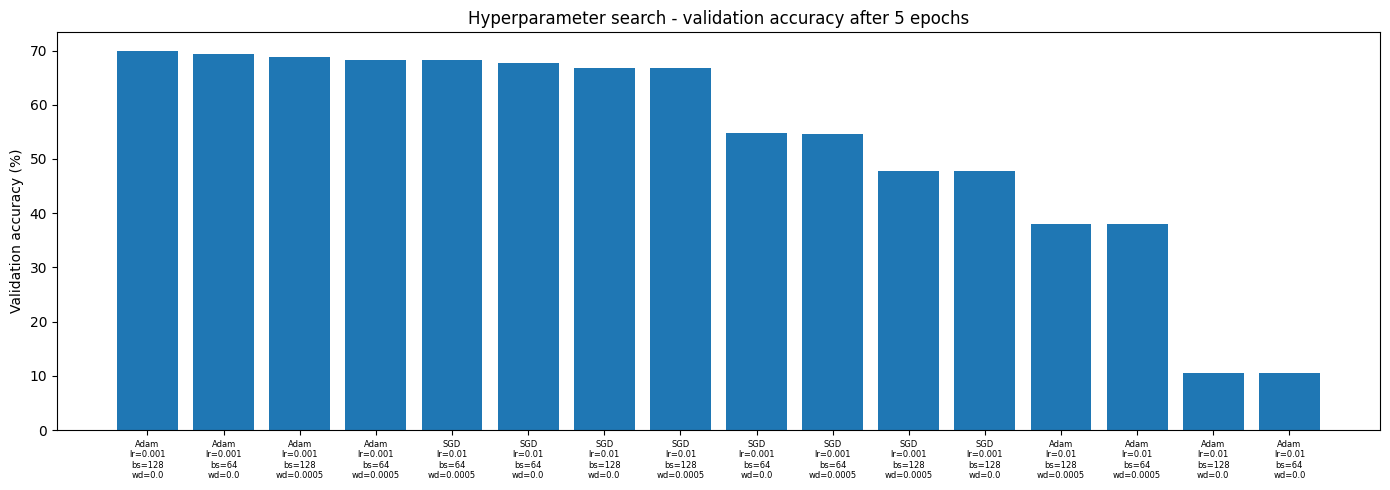

Best config: {'lr': 0.001, 'optimizer': 'Adam', 'batch_size': 128, 'wd': 0.0}


In [17]:
# Plot: validation accuracy per configuration
labels = [f"{r.optimizer}\nlr={r.lr}\nbs={r.batch_size}\nwd={r.wd}" for r in tune_df.itertuples()]
plt.figure(figsize=(14, 5))
plt.bar(range(len(tune_df)), tune_df["final_val_acc"])
plt.xticks(range(len(tune_df)), labels, fontsize=6)
plt.ylabel("Validation accuracy (%)")
plt.title("Hyperparameter search - validation accuracy after 5 epochs")
plt.tight_layout()
plt.savefig("results/tuning_val_acc.png", dpi=150)
plt.show()

best = tune_df.iloc[0]
best_cfg = {"lr": float(best.lr), "optimizer": best.optimizer,
            "batch_size": int(best.batch_size), "wd": float(best.wd)}
print("Best config:", best_cfg)

In [18]:
# Final training with the best config
FINAL_EPOCHS = 20
torch.manual_seed(SEED)
final_train_loader = DataLoader(train_ds, batch_size=best_cfg["batch_size"], shuffle=True, num_workers=2)
final_model, hist = fit(best_cfg, FINAL_EPOCHS, final_train_loader, val_loader, verbose=True)

# Record per-epoch losses & accuracy
hist_df = pd.DataFrame(hist)
hist_df.insert(0, "epoch", range(1, FINAL_EPOCHS + 1))
hist_df.to_csv("results/training_history.csv", index=False)
hist_df.round(4)

Epoch 1/20 | Train Loss 1.6106 Acc 41.39% | Val Loss 1.3128 Acc 52.82%
Epoch 2/20 | Train Loss 1.2639 Acc 54.61% | Val Loss 1.0992 Acc 60.26%
Epoch 3/20 | Train Loss 1.1094 Acc 60.56% | Val Loss 0.9917 Acc 64.86%
Epoch 4/20 | Train Loss 1.0156 Acc 63.91% | Val Loss 0.9360 Acc 67.50%
Epoch 5/20 | Train Loss 0.9643 Acc 65.97% | Val Loss 0.8714 Acc 69.80%
Epoch 6/20 | Train Loss 0.9116 Acc 67.73% | Val Loss 0.8457 Acc 70.38%
Epoch 7/20 | Train Loss 0.8735 Acc 69.13% | Val Loss 0.8192 Acc 71.74%
Epoch 8/20 | Train Loss 0.8457 Acc 70.13% | Val Loss 0.7882 Acc 72.86%
Epoch 9/20 | Train Loss 0.8159 Acc 71.44% | Val Loss 0.8254 Acc 71.86%
Epoch 10/20 | Train Loss 0.7901 Acc 72.28% | Val Loss 0.7686 Acc 73.72%
Epoch 11/20 | Train Loss 0.7681 Acc 73.07% | Val Loss 0.7468 Acc 74.38%
Epoch 12/20 | Train Loss 0.7439 Acc 73.80% | Val Loss 0.7234 Acc 75.60%
Epoch 13/20 | Train Loss 0.7286 Acc 74.46% | Val Loss 0.7180 Acc 75.56%
Epoch 14/20 | Train Loss 0.7187 Acc 74.89% | Val Loss 0.7238 Acc 75.18%
E

,epoch,train_loss,train_acc,val_loss,val_acc
0,1,1.6106,41.3911,1.3128,52.82
1,2,1.2639,54.6133,1.0992,60.26
2,3,1.1094,60.5578,0.9917,64.86
3,4,1.0156,63.9089,0.9360,67.50
4,5,0.9643,65.9689,0.8714,69.80
5,6,0.9116,67.7289,0.8457,70.38
6,7,0.8735,69.1311,0.8192,71.74
7,8,0.8457,70.1311,0.7882,72.86
8,9,0.8159,71.4422,0.8254,71.86
9,10,0.7901,72.2756,0.7686,73.72


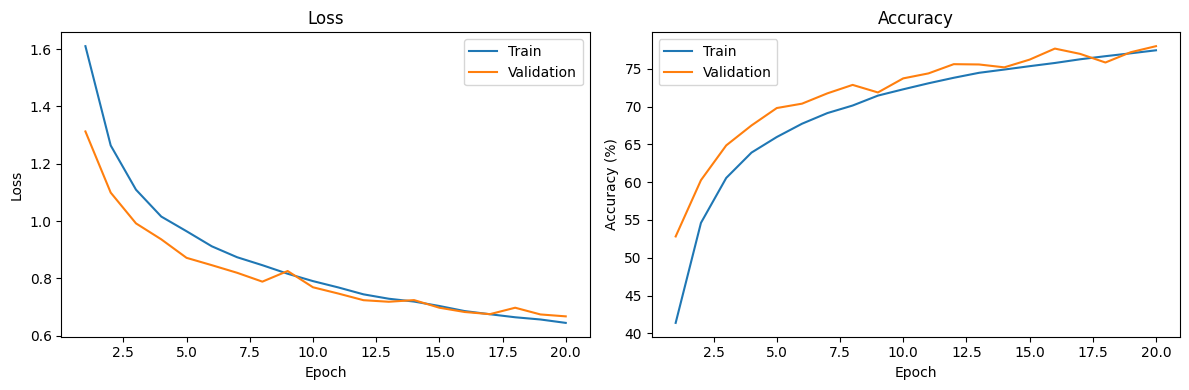

In [19]:
# Loss and accuracy curves
epochs_x = range(1, FINAL_EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs_x, hist["train_loss"], label="Train")
ax[0].plot(epochs_x, hist["val_loss"], label="Validation")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Loss"); ax[0].set_title("Loss"); ax[0].legend()

ax[1].plot(epochs_x, hist["train_acc"], label="Train")
ax[1].plot(epochs_x, hist["val_acc"], label="Validation")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy (%)"); ax[1].set_title("Accuracy"); ax[1].legend()

plt.tight_layout()
plt.savefig("results/loss_accuracy_curves.png", dpi=150)
plt.show()

In [20]:
# Final evaluation on the held-out test set
criterion = nn.CrossEntropyLoss()
test_loss, test_acc = evaluate(final_model, test_loader, criterion)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.2f}%")

summary = {"best_config": best_cfg, "epochs": FINAL_EPOCHS,
           "final_train_loss": hist["train_loss"][-1], "final_train_acc": hist["train_acc"][-1],
           "final_val_loss": hist["val_loss"][-1], "final_val_acc": hist["val_acc"][-1],
           "test_loss": test_loss, "test_acc": test_acc}
json.dump(summary, open("results/summary.json", "w"), indent=2)
torch.save(final_model.state_dict(), "results/cnn_cifar10.pth")
summary

Test Loss: 0.6635 | Test Accuracy: 77.14%


{'best_config': {'lr': 0.001,
  'optimizer': 'Adam',
  'batch_size': 128,
  'wd': 0.0},
 'epochs': 20,
 'final_train_loss': 0.6441984263526069,
 'final_train_acc': 77.43333333333334,
 'final_val_loss': 0.6669819930076599,
 'final_val_acc': 77.98,
 'test_loss': 0.6634527311325074,
 'test_acc': 77.14}